# Affordable Produce and Recipe Recommendation
## Data Collection, Cleaning, and Exploratory Analysis

### Project Objective
The goal of this project is to investigate produce prices trends over time.


## Imports and project setup

In [3]:
from pathlib import Path
from getpass import getpass
from requests.auth import HTTPBasicAuth

import os
import re
import json
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR = PROJECT_DIR / "report"

for folder in [RAW_DIR, PROCESSED_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)
print("Report directory:", REPORT_DIR)

Project directory: /mnt/c/Users/benny/csci_code/csci_413/produce-recommender
Raw data directory: /mnt/c/Users/benny/csci_code/csci_413/produce-recommender/data/raw
Processed data directory: /mnt/c/Users/benny/csci_code/csci_413/produce-recommender/data/processed
Report directory: /mnt/c/Users/benny/csci_code/csci_413/produce-recommender/report


## Check CSV files in raw data folder can be accessed

In [4]:
raw_files = sorted(RAW_DIR.glob("*.csv"))

print("CSV files found:", len(raw_files))

for file_path in raw_files:
    print(f"\n{'=' * 60}")
    print("Filename:", file_path.name)

    try:
        preview = pd.read_csv(file_path)
        print("Columns:", preview.columns.tolist())
        display(preview.shape)
    except Exception as error:
        print("Could not read this CSV:", error)

CSV files found: 5

Filename: PP_recipes.csv
Columns: ['id', 'i', 'name_tokens', 'ingredient_tokens', 'steps_tokens', 'techniques', 'calorie_level', 'ingredient_ids']


(178265, 8)


Filename: fruit-prices-2023.csv
Columns: ['Fruit', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']


(62, 8)


Filename: kroger_produce_raw.csv
Columns: ['search_term', 'product_id', 'upc', 'description', 'brand', 'size', 'regular_price', 'promo_price', 'store_id', 'collection_date']


(79, 10)


Filename: kroger_stores.csv
Columns: ['location_id', 'store_name', 'address', 'city', 'state', 'zip_code']


(10, 6)


Filename: vegetable-prices-2023.csv
Columns: ['Vegetable', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']


(93, 8)

## Use Kroger API to collect store locations

In [9]:
client_id = os.getenv("KROGER_CLIENT_ID")
client_secret = os.getenv("KROGER_CLIENT_SECRET")

if not client_id:
    client_id = getpass("Kroger client ID (input hidden): ")

if not client_secret:
    client_secret = getpass("Kroger client secret (input hidden): ")

zip_code = input("ZIP code for your grocery search: ").strip()

TOKEN_URL = "https://api.kroger.com/v1/connect/oauth2/token"
BASE_URL = "https://api.kroger.com/v1"

token_response = requests.post(
    TOKEN_URL,
    auth=HTTPBasicAuth(client_id, client_secret),
    data={
        "grant_type": "client_credentials",
        "scope": "product.compact"
    },
    timeout=30
)

print("Token status:", token_response.status_code)
token_response.raise_for_status()

access_token = token_response.json()["access_token"]

headers = {
    "Authorization": f"Bearer {access_token}",
    "Accept": "application/json"
}

location_response = requests.get(
    f"{BASE_URL}/locations",
    headers=headers,
    params={
        "filter.zipCode.near": zip_code,
        "filter.limit": 10
    },
    timeout=30
)

print("Location status:", location_response.status_code)
location_response.raise_for_status()

locations = location_response.json().get("data", [])
location_rows = []

for location in locations:
    address = location.get("address", {})

    location_rows.append({
        "location_id": location.get("locationId"),
        "store_name": location.get("name"),
        "address": address.get("addressLine1"),
        "city": address.get("city"),
        "state": address.get("state"),
        "zip_code": address.get("zipCode")
    })

stores_df = pd.DataFrame(location_rows)
display(stores_df)

if stores_df.empty:
    raise ValueError(
        "No locations returned."
    )

Kroger client ID (input hidden):  ········
Kroger client secret (input hidden):  ········
ZIP code for your grocery search:  80236


Token status: 200
Location status: 200


,location_id,store_name,address,city,state,zip_code
0,62000019,King Soopers - BEAR VALLEY,3100 S Sheridan Blvd,Denver,CO,80227
1,62000109,King Soopers - Federal and Belleview,5050 S Federal Blvd,Englewood,CO,80110
2,62000056,King Soopers - W Evans Ave,2727 W Evans Ave,Denver,CO,80219
3,62000065,King Soopers - Englewood Pkwy and S Broadway,101 Englewood Pkwy,Englewood,CO,80110
4,62000007,King Soopers - W Florida Ave,5125 W Florida Ave,Denver,CO,80219
5,62000031,King Soopers - Jewell and Wadsworth,1927 S Wadsworth Blvd,Lakewood,CO,80227
6,62000131,King Soopers - Littleton and Broadway,100 W Littleton Blvd,Littleton,CO,80120
7,62000050,King Soopers - Governors Plaza,9820 W Belleview Ave,Littleton,CO,80123
8,62000111,King Soopers Fresh Fare - Fresh Fare,3495 S University Blvd,Englewood,CO,80113
9,62000041,King Soopers - Coalmine and Pierce,6760 S Pierce St,Littleton,CO,80128


### Selecting a store and loading datasets

In [23]:
# Select up to three stores and collect a new point-in-time price snapshot.
number_of_stores = min(3, len(stores_df))
selected_stores = stores_df.head(number_of_stores).copy()

if selected_stores.empty:
    raise ValueError("No stores are available. Check the ZIP code and location lookup.")

if selected_stores["location_id"].isna().any():
    raise ValueError("One or more selected stores are missing a location ID.")

stores_df.to_csv(RAW_DIR / "kroger_stores.csv", index=False)

print("Stores selected:")
display(selected_stores[["location_id", "store_name", "city", "state"]])

search_terms = [
    "bananas", "apples", "potatoes", "carrots",
    "broccoli", "onions", "tomatoes", "bell pepper"
]

# One timestamp for this collection run; keep the timezone.
collected_at = pd.Timestamp.now(tz="America/Denver").floor("s")
collection_date = collected_at.strftime("%Y-%m-%d")
collection_timestamp = collected_at.isoformat()

product_rows = []

for _, store in selected_stores.iterrows():
    store_id = str(store["location_id"]).strip()
    store_name = store.get("store_name")

    print(f"\nCollecting prices at {store_name} (ID: {store_id})")

    for term in search_terms:
        response = requests.get(
            f"{BASE_URL}/products",
            headers=headers,
            params={
                "filter.term": term,
                "filter.locationId": store_id,
                "filter.limit": 10
            },
            timeout=30
        )

        print(f"{term}: HTTP {response.status_code}")
        response.raise_for_status()

        products = response.json().get("data", [])

        for product in products:
            for item in product.get("items", []):
                price = item.get("price") or {}

                product_rows.append({
                    "search_term": term,
                    "product_id": str(product.get("productId") or ""),
                    "upc": str(product.get("upc") or ""),
                    "description": product.get("description"),
                    "brand": product.get("brand"),
                    "size": item.get("size"),
                    "regular_price": price.get("regular"),
                    "promo_price": price.get("promo"),
                    "store_id": store_id,
                    "store_name": store_name,
                    "collection_date": collection_date,
                    "collection_timestamp": collection_timestamp
                })

        time.sleep(0.25)

new_snapshot = pd.DataFrame(product_rows)

if new_snapshot.empty:
    print("No products returned. Existing price history was not changed.")
else:
    history_path = RAW_DIR / "kroger_produce_raw.csv"

    if history_path.exists():
        old_history = pd.read_csv(
            history_path,
            dtype={"product_id": "string", "upc": "string", "store_id": "string"},
            low_memory=False
        )

        # Add fields that may be absent in older versions of the file.
        for column in [
            "search_term", "product_id", "upc", "description", "brand",
            "size", "regular_price", "promo_price", "store_id",
            "store_name", "collection_date", "collection_timestamp"
        ]:
            if column not in old_history.columns:
                old_history[column] = pd.NA

        # Recover store names from known store IDs where possible.
        store_name_map = {
            str(row["location_id"]).strip(): row["store_name"]
            for _, row in stores_df.iterrows()
            if pd.notna(row.get("location_id")) and pd.notna(row.get("store_name"))
        }
        old_history["store_id"] = old_history["store_id"].astype("string").str.strip()
        old_history["store_name"] = old_history["store_name"].fillna(
            old_history["store_id"].map(store_name_map)
        )

        # Recover dates from existing timestamps only; never invent original timestamps.
        old_timestamps = pd.to_datetime(
            old_history["collection_timestamp"], errors="coerce", utc=True
        )
        missing_dates = old_history["collection_date"].isna() | (
            old_history["collection_date"].astype("string").str.strip() == ""
        )
        recoverable_dates = missing_dates & old_timestamps.notna()
        old_history.loc[recoverable_dates, "collection_date"] = (
            old_timestamps.loc[recoverable_dates]
            .dt.tz_convert("America/Denver")
            .dt.strftime("%Y-%m-%d")
        )

        history = pd.concat(
            [old_history, new_snapshot],
            ignore_index=True,
            sort=False
        )
    else:
        history = new_snapshot.copy()

    # Remove exact duplicate rows, but do not collapse older observations that
    # have missing timestamps: their dates may still distinguish the snapshots.
    history = history.drop_duplicates().reset_index(drop=True)

    # For records with timestamps, keep one row per product/store/size/timestamp.
    timestamp_values = pd.to_datetime(
        history["collection_timestamp"], errors="coerce", utc=True
    )
    has_timestamp = timestamp_values.notna()
    dedup_columns = [
        col for col in [
            "store_id", "product_id", "upc", "size", "collection_timestamp"
        ] if col in history.columns
    ]

    timestamped = history.loc[has_timestamp].drop_duplicates(
        subset=dedup_columns, keep="last"
    )
    untimestamped = history.loc[~has_timestamp]
    history = pd.concat(
        [untimestamped, timestamped], ignore_index=True, sort=False
    ).drop_duplicates().reset_index(drop=True)

    history.to_csv(history_path, index=False)

    print("\nProducts collected this run:", len(new_snapshot))
    print("Total rows in price history:", len(history))
    print("Saved to:", history_path)
    display(new_snapshot.head(10))


Stores selected:


,location_id,store_name,city,state
0,62000019,King Soopers - BEAR VALLEY,Denver,CO
1,62000109,King Soopers - Federal and Belleview,Englewood,CO
2,62000056,King Soopers - W Evans Ave,Denver,CO



bananas: HTTP 401


HTTPError: 401 Client Error: Unauthorized for url: https://api.kroger.com/v1/products?filter.term=bananas&filter.locationId=62000019&filter.limit=10

In [13]:
# Load raw datasets. Recipe data is optional for the current price-trend project.
raw_datasets = {}
load_errors = []

files_to_load = [
    ("kroger_produce_raw.csv", "kroger_produce"),
    ("fruit-prices-2023.csv", "fruit-prices-2023"),
    ("vegetable-prices-2023.csv", "vegetable-prices-2023"),
    ("PP_recipes.csv", "PP_recipes")
]

for filename, dataset_name in files_to_load:
    file_path = RAW_DIR / filename

    if not file_path.exists():
        print(f"Not found, skipping optional/unavailable file: {filename}")
        continue

    try:
        if filename == "kroger_produce_raw.csv":
            df = pd.read_csv(
                file_path,
                dtype={
                    "product_id": "string",
                    "upc": "string",
                    "store_id": "string"
                },
                low_memory=False
            )
        else:
            df = pd.read_csv(file_path, low_memory=False)

        raw_datasets[dataset_name] = df
        print(f"Loaded {filename}: {df.shape[0]:,} rows and {df.shape[1]:,} columns")

    except Exception as error:
        load_errors.append({"file": filename, "error": str(error)})

if load_errors:
    print("\nFiles that could not be loaded:")
    display(pd.DataFrame(load_errors))

if "kroger_produce" not in raw_datasets:
    raise FileNotFoundError(
        f"Could not load {RAW_DIR / 'kroger_produce_raw.csv'}. "
        "Run the Kroger collection cell successfully first."
    )

# Recover store names using the saved store lookup (and the current lookup if available).
store_lookup_path = RAW_DIR / "kroger_stores.csv"
store_lookup = stores_df.copy() if "stores_df" in globals() else pd.DataFrame()

if store_lookup_path.exists():
    saved_lookup = pd.read_csv(store_lookup_path, dtype={"location_id": "string"})
    store_lookup = pd.concat([store_lookup, saved_lookup], ignore_index=True)
    store_lookup = store_lookup.drop_duplicates(subset=["location_id"], keep="last")

if not store_lookup.empty and {"location_id", "store_name"}.issubset(store_lookup.columns):
    store_name_map = {
        str(row["location_id"]).strip(): row["store_name"]
        for _, row in store_lookup.iterrows()
        if pd.notna(row["location_id"]) and pd.notna(row["store_name"])
    }

    kroger_df = raw_datasets["kroger_produce"]
    if "store_id" in kroger_df.columns:
        kroger_df["store_id"] = kroger_df["store_id"].astype("string").str.strip()
        if "store_name" not in kroger_df.columns:
            kroger_df["store_name"] = pd.NA
        kroger_df["store_name"] = kroger_df["store_name"].fillna(
            kroger_df["store_id"].map(store_name_map)
        )
        raw_datasets["kroger_produce"] = kroger_df

# Ensure date fields exist, then fill a missing date only from a valid recorded timestamp.
kroger_df = raw_datasets["kroger_produce"]
for column in ["collection_date", "collection_timestamp", "store_name"]:
    if column not in kroger_df.columns:
        kroger_df[column] = pd.NA

parsed_timestamps = pd.to_datetime(
    kroger_df["collection_timestamp"], errors="coerce", utc=True
)
date_values = pd.to_datetime(kroger_df["collection_date"], errors="coerce")
missing_dates = date_values.isna()
recoverable_dates = missing_dates & parsed_timestamps.notna()

date_values.loc[recoverable_dates] = (
    parsed_timestamps.loc[recoverable_dates]
    .dt.tz_convert("America/Denver")
    .dt.tz_localize(None)
)
kroger_df["collection_date"] = date_values.dt.strftime("%Y-%m-%d")
raw_datasets["kroger_produce"] = kroger_df

# Save only the schema repairs/recoverable metadata; original prices are not imputed.
kroger_df.to_csv(RAW_DIR / "kroger_produce_raw.csv", index=False)


Loaded kroger_produce_raw.csv: 316 rows and 12 columns
Loaded fruit-prices-2023.csv: 62 rows and 8 columns
Loaded vegetable-prices-2023.csv: 93 rows and 8 columns


## Inspecting data's statistics and values then fix the formatting of the data

In [14]:
def inspect_dataset(df, name="Dataset"):
    print(f"\n{'=' * 70}")
    print("DATASET:", name)
    print(f"{'=' * 70}")

    print("Shape:", df.shape)
    print("Exact duplicate rows:", int(df.duplicated().sum()))
    print("Completely empty rows:", int(df.isna().all(axis=1).sum()))
    print("Completely empty columns:", int(df.isna().all(axis=0).sum()))

    print("\nData types:")
    display(df.dtypes.rename("dtype").to_frame())

    print("\nMissing-value summary:")
    missing = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_nonmissing": df.nunique(dropna=True)
    }).sort_values("missing_percent", ascending=False)

    display(missing)

    print("\nDescriptive statistics:")
    display(df.describe(include="all").T)

    print("\nSample records:")
    display(df.head())

for name, df in raw_datasets.items():
    inspect_dataset(df, name)


DATASET: kroger_produce
Shape: (316, 12)
Exact duplicate rows: 0
Completely empty rows: 0
Completely empty columns: 0

Data types:


,dtype
search_term,str
product_id,string
upc,string
description,str
brand,str
size,str
regular_price,float64
promo_price,float64
store_id,int64
collection_date,str



Missing-value summary:


,missing_count,missing_percent,unique_nonmissing
promo_price,267,84.49,13
collection_date,237,75.00,1
brand,96,30.38,17
collection_timestamp,79,25.00,1
store_name,79,25.00,3
regular_price,1,0.32,44
product_id,0,0.00,93
search_term,0,0.00,8
description,0,0.00,90
upc,0,0.00,93



Descriptive statistics:


...

,missing_count,missing_percent,unique_nonmissing
Vegetable,0,0.0,65
Form,0,0.0,4
AverageRetailPrice,0,0.0,90
AverageRetailPriceUnitOfMeasure,0,0.0,1
PreparationYieldFactor,0,0.0,46
SizeOfACupEquivalent,0,0.0,22
CupEquivalentUnitOfMeasure,0,0.0,1
AveragePricePerCupEquivalent,0,0.0,93



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Vegetable,93,65,Asparagus,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Form,93,4,Fresh,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AverageRetailPrice,93.0,NaN,NaN,NaN,2.226094,1.144051,0.826627,1.327845,1.996333,2.719125,6.780905
AverageRetailPriceUnitOfMeasure,93,1,per pound,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PreparationYieldFactor,93.0,NaN,NaN,NaN,0.959997,0.494943,0.375,0.65,0.8818,0.9702,2.5397
SizeOfACupEquivalent,93.0,NaN,NaN,NaN,0.338635,0.066544,0.1543,0.2976,0.3417,0.3858,0.5401
CupEquivalentUnitOfMeasure,93,1,pounds,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AveragePricePerCupEquivalent,93.0,NaN,NaN,NaN,0.874722,0.536705,0.234756,0.550156,0.732716,0.996849,2.603951



Sample records:


,Vegetable,Form,AverageRetailPrice,AverageRetailPriceUnitOfMeasure,PreparationYieldFactor,SizeOfACupEquivalent,CupEquivalentUnitOfMeasure,AveragePricePerCupEquivalent
0,Acorn squash,Fresh,1.241439,per pound,0.4586,0.4519,pounds,1.223533
1,Artichoke,Fresh,2.506856,per pound,0.3750,0.3858,pounds,2.080461
2,Artichoke,Canned,3.505101,per pound,0.6500,0.3858,pounds,2.579113
3,Asparagus,Fresh,3.212453,per pound,0.4938,0.3968,pounds,2.581436
4,Asparagus,Canned,3.676296,per pound,0.6500,0.3968,pounds,2.244419


In [18]:
print("Available datasets:", raw_datasets.keys())

for name, df in raw_datasets.items():
    print(f"\nDataset: {name}")
    print("DataFrame shape:", df.shape)
    print("Columns:", df.columns.tolist())

Available datasets: dict_keys(['kroger_produce', 'fruit-prices-2023', 'vegetable-prices-2023'])

Dataset: kroger_produce
DataFrame shape: (316, 12)
Columns: ['search_term', 'product_id', 'upc', 'description', 'brand', 'size', 'regular_price', 'promo_price', 'store_id', 'collection_date', 'collection_timestamp', 'store_name']

Dataset: fruit-prices-2023
DataFrame shape: (62, 8)
Columns: ['Fruit', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']

Dataset: vegetable-prices-2023
DataFrame shape: (93, 8)
Columns: ['Vegetable', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']


In [15]:
def clean_dataframe(df):
    cleaned = df.copy()

    original_rows = len(cleaned)
    original_columns = len(cleaned.columns)
    original_missing_cells = int(cleaned.isna().sum().sum())
    original_duplicate_rows = int(cleaned.duplicated().sum())

    # Standardize column names
    cleaned.columns = [
        re.sub(
            r"_+",
            "_",
            re.sub(r"[^a-z0-9]+", "_", str(col).strip().lower())
        ).strip("_")
        for col in cleaned.columns
    ]

    # Detect duplicate column names created during standardization
    if cleaned.columns.duplicated().any():
        duplicate_names = cleaned.columns[
            cleaned.columns.duplicated()
        ].tolist()

        raise ValueError(
            f"Duplicate column names after normalization: {duplicate_names}"
        )

    # Remove fully empty rows and columns
    cleaned = cleaned.dropna(axis=0, how="all")
    cleaned = cleaned.dropna(axis=1, how="all")

    # Normalize whitespace and common missing-value markers
    missing_markers = {
        "": np.nan,
        "na": np.nan,
        "n/a": np.nan,
        "null": np.nan,
        "none": np.nan,
        "nan": np.nan,
        "unknown": np.nan
    }

    for col in cleaned.select_dtypes(include=["object", "string"]).columns:
        cleaned[col] = cleaned[col].map(
            lambda x: x.strip() if isinstance(x, str) else x
        )

        cleaned[col] = cleaned[col].map(
            lambda x: missing_markers.get(x.lower(), x)
            if isinstance(x, str) else x
        )

    # Remove exact duplicate rows
    cleaned = cleaned.drop_duplicates().reset_index(drop=True)

    audit = {
        "original_rows": original_rows,
        "cleaned_rows": len(cleaned),
        "rows_removed": original_rows - len(cleaned),
        "original_columns": original_columns,
        "cleaned_columns": len(cleaned.columns),
        "original_missing_cells": original_missing_cells,
        "cleaned_missing_cells": int(cleaned.isna().sum().sum()),
        "original_duplicate_rows": original_duplicate_rows,
        "remaining_duplicate_rows": int(cleaned.duplicated().sum())
    }

    return cleaned, audit


cleaned_datasets = {}
cleaning_results = []

for name, df in raw_datasets.items():
    cleaned_df, audit = clean_dataframe(df)

    if name == "kroger_produce":
        # Parse timestamps
        cleaned_df["collection_timestamp"] = pd.to_datetime(
            cleaned_df["collection_timestamp"],
            errors="coerce"
        )

        # Ensure product identifiers remain strings
        for column in ["product_id", "upc", "store_id"]:
            if column in cleaned_df.columns:
                cleaned_df[column] = cleaned_df[column].astype("string")

    cleaned_datasets[name] = cleaned_df

    audit["dataset"] = name
    cleaning_results.append(audit)

    output_path = PROCESSED_DIR / f"{name}_cleaned.csv"
    cleaned_df.to_csv(output_path, index=False)

    print(f"Saved: {output_path}")

cleaning_audit = pd.DataFrame(cleaning_results)
display(cleaning_audit)

cleaning_audit.to_csv(
    REPORT_DIR / "cleaning_audit.csv",
    index=False
)

Saved: /mnt/c/Users/benny/csci_code/csci_413/produce-recommender/data/processed/kroger_produce_cleaned.csv
Saved: /mnt/c/Users/benny/csci_code/csci_413/produce-recommender/data/processed/fruit-prices-2023_cleaned.csv
Saved: /mnt/c/Users/benny/csci_code/csci_413/produce-recommender/data/processed/vegetable-prices-2023_cleaned.csv


,original_rows,cleaned_rows,rows_removed,original_columns,cleaned_columns,original_missing_cells,cleaned_missing_cells,original_duplicate_rows,remaining_duplicate_rows,dataset
0,316,316,0,12,12,759,759,0,0,kroger_produce
1,62,62,0,8,8,0,0,0,0,fruit-prices-2023
2,93,93,0,8,8,0,0,0,0,vegetable-prices-2023


### Recheck our stats with the new cleaned datasets

In [16]:
quality_results = []

for name, df in cleaned_datasets.items():
    quality_results.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_percent": round(
            df.isna().sum().sum() / max(df.size, 1) * 100, 2
        ),
        "fully_empty_rows": int(df.isna().all(axis=1).sum())
    })

quality_summary = pd.DataFrame(quality_results)
display(quality_summary)

quality_summary.to_csv(
    REPORT_DIR / "data_quality_summary.csv",
    index=False
)

,dataset,rows,columns,duplicate_rows,missing_cells,missing_percent,fully_empty_rows
0,kroger_produce,316,12,0,759,20.02,0
1,fruit-prices-2023,62,8,0,0,0.00,0
2,vegetable-prices-2023,93,8,0,0,0.00,0


In [21]:
kroger_df = raw_datasets["kroger_produce"]

date_check = kroger_df[
    kroger_df["collection_date"].isna()
    | kroger_df["collection_timestamp"].isna()
][[
    "collection_date",
    "collection_timestamp",
    "store_name",
    "store_id",
    "product_id",
    "regular_price"
]]

display(date_check.head(20))

print("Total rows:", len(kroger_df))
print("Missing collection_date:", kroger_df["collection_date"].isna().sum())
print("Missing collection_timestamp:", kroger_df["collection_timestamp"].isna().sum())
print(
    "Both date fields missing:",
    (
        kroger_df["collection_date"].isna()
        & kroger_df["collection_timestamp"].isna()
    ).sum()
)

,collection_date,collection_timestamp,store_name,store_id,product_id,regular_price
0,2026-10-15,NaN,NaN,62000019,0000000004011,0.55
1,2026-10-15,NaN,NaN,62000019,0000000094011,0.79
2,2026-10-15,NaN,NaN,62000019,0000000004235,0.67
3,2026-10-15,NaN,NaN,62000019,0008259219415,3.79
4,2026-10-15,NaN,NaN,62000019,0008259219464,8.99
5,2026-10-15,NaN,NaN,62000019,0001111011379,4.99
6,2026-10-15,NaN,NaN,62000019,0001111063660,8.99
7,2026-10-15,NaN,NaN,62000019,0001397100502,6.29
8,2026-10-15,NaN,NaN,62000019,0000000004757,NaN
9,2026-10-15,NaN,NaN,62000019,0000000003283,2.49


Total rows: 316
Missing collection_date: 237
Missing collection_timestamp: 79
Both date fields missing: 0


In [22]:
cleaned_kroger = cleaned_datasets["kroger_produce"]

print(cleaned_kroger["collection_timestamp"].dtype)
print(cleaned_kroger["collection_timestamp"].head(10))

datetime64[us]
0   NaT
1   NaT
2   NaT
3   NaT
4   NaT
5   NaT
6   NaT
7   NaT
8   NaT
9   NaT
Name: collection_timestamp, dtype: datetime64[us]


### Find grocery price and validate each row's prices then check our dataset for outliers using IQR

In [11]:
price_dataset_name = None

for name, df in cleaned_datasets.items():
    if any(
        col in df.columns
        for col in ["effective_price", "regular_price", "promo_price", "price"]
    ):
        price_dataset_name = name
        break

if price_dataset_name is None:
    print("No recognizable price dataset found.")
    print("Inspect Cell 8 and identify the dataset and price column manually.")
else:
    prices = cleaned_datasets[price_dataset_name].copy()

    print("Selected price dataset:", price_dataset_name)
    print("Available columns:", prices.columns.tolist())

    # Convert known price columns to numeric, preserving unparseable values as NaN.
    price_columns = [
        col for col in ["effective_price", "regular_price", "promo_price", "price"]
        if col in prices.columns
    ]

    for col in price_columns:
        prices[col] = pd.to_numeric(prices[col], errors="coerce")

    # Calculate effective price for Kroger-style data if needed.
    if (
        "effective_price" not in prices.columns
        and "regular_price" in prices.columns
        and "promo_price" in prices.columns
    ):
        promo_valid = (
            prices["promo_price"].notna()
            & (prices["promo_price"] > 0)
        )

        prices["effective_price"] = prices["regular_price"]
        prices.loc[promo_valid, "effective_price"] = prices.loc[
            promo_valid, "promo_price"
        ]

        prices["price_source"] = np.where(
            promo_valid, "promotion", "regular"
        )

    selected_price_column = (
        "effective_price"
        if "effective_price" in prices.columns
        else price_columns[0]
    )

    prices["price_missing"] = prices[selected_price_column].isna()

    prices["price_nonpositive"] = (
        prices[selected_price_column].notna()
        & (prices[selected_price_column] <= 0)
    )

    print("Price column:", selected_price_column)
    print("Missing prices:", int(prices["price_missing"].sum()))
    print("Zero or negative prices:", int(prices["price_nonpositive"].sum()))

    display(
        prices.loc[
            prices["price_missing"] | prices["price_nonpositive"]
        ].head(20)
    )

    prices.to_csv(
        PROCESSED_DIR / f"{price_dataset_name}_price_checked.csv",
        index=False
    )

Selected price dataset: kroger_produce_raw
Available columns: ['search_term', 'product_id', 'upc', 'description', 'brand', 'size', 'regular_price', 'promo_price', 'store_id', 'collection_date']
Price column: effective_price
Missing prices: 1
Zero or negative prices: 0


,search_term,product_id,upc,description,brand,size,regular_price,promo_price,store_id,collection_date,effective_price,price_source,price_missing,price_nonpositive
8,bananas,4757,4757,Banana Squash,NaN,1 lb,NaN,NaN,62000019,2026-10-15,NaN,regular,True,False


In [12]:
if price_dataset_name is not None:
    values = prices[selected_price_column].dropna()

    if len(values) >= 4:
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        prices["potential_price_outlier"] = (
            prices[selected_price_column].lt(lower_bound)
            | prices[selected_price_column].gt(upper_bound)
        ).fillna(False)

        print("Q1:", q1)
        print("Q3:", q3)
        print("IQR:", iqr)
        print("Lower bound:", lower_bound)
        print("Upper bound:", upper_bound)
        print(
            "Potential outliers:",
            int(prices["potential_price_outlier"].sum())
        )

        display(
            prices.loc[
                prices["potential_price_outlier"],
                [
                    col for col in [
                        "description", "search_term", "size",
                        selected_price_column
                    ]
                    if col in prices.columns
                ]
            ].head(30)
        )

        prices.to_csv(
            PROCESSED_DIR / f"{price_dataset_name}_outlier_checked.csv",
            index=False
        )
    else:
        print("Not enough nonmissing price values for a useful IQR check.")
else:
    print("No price dataset selected.")
    

Q1: 1.69
Q3: 3.99
IQR: 2.3000000000000003
Lower bound: -1.7600000000000002
Upper bound: 7.44
Potential outliers: 3


,description,search_term,size,effective_price
4,Naked Boosted Smoothie Strawberry Banana Machine,bananas,64 fl oz,8.99
6,Simple Truth® Berries and Banana Trail Mix,bananas,16 oz,8.99
27,Kroger® Gold Potatoes,potatoes,5 lb,7.79


### Distribution and Correlation Check using visualizations


Numeric feature distributions: PP_recipes


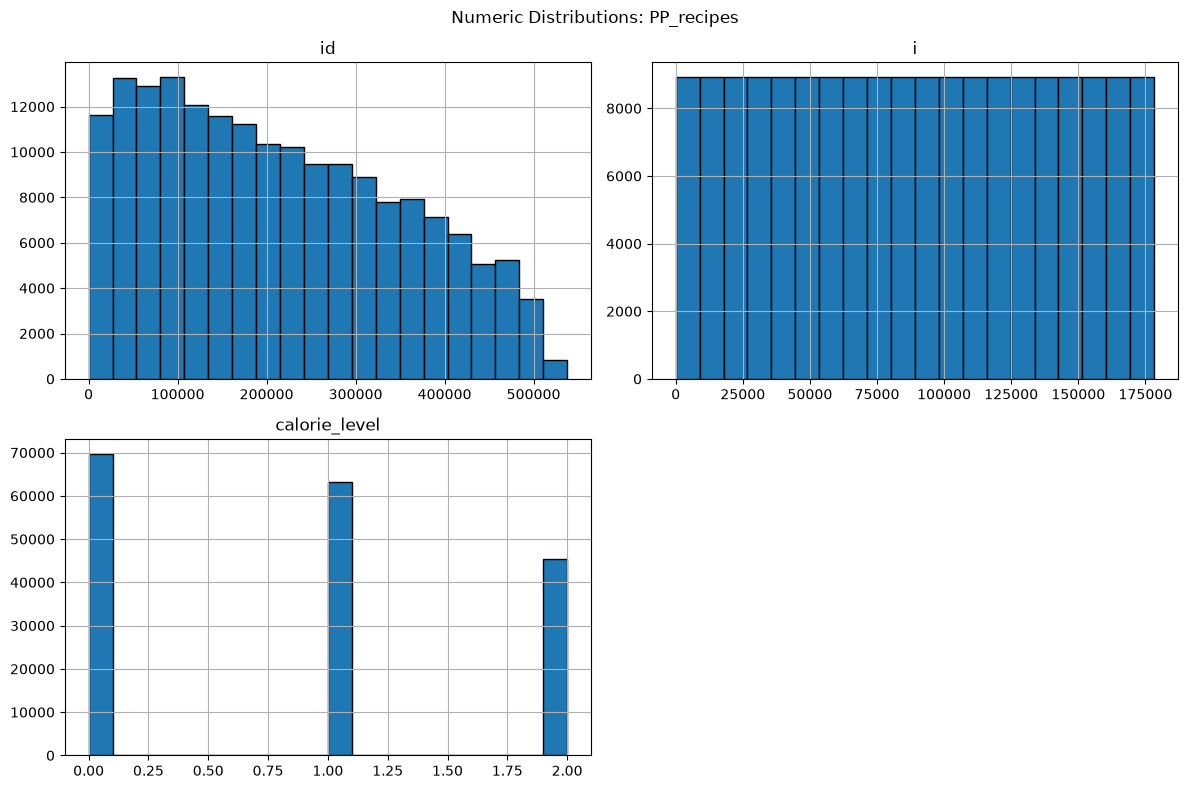

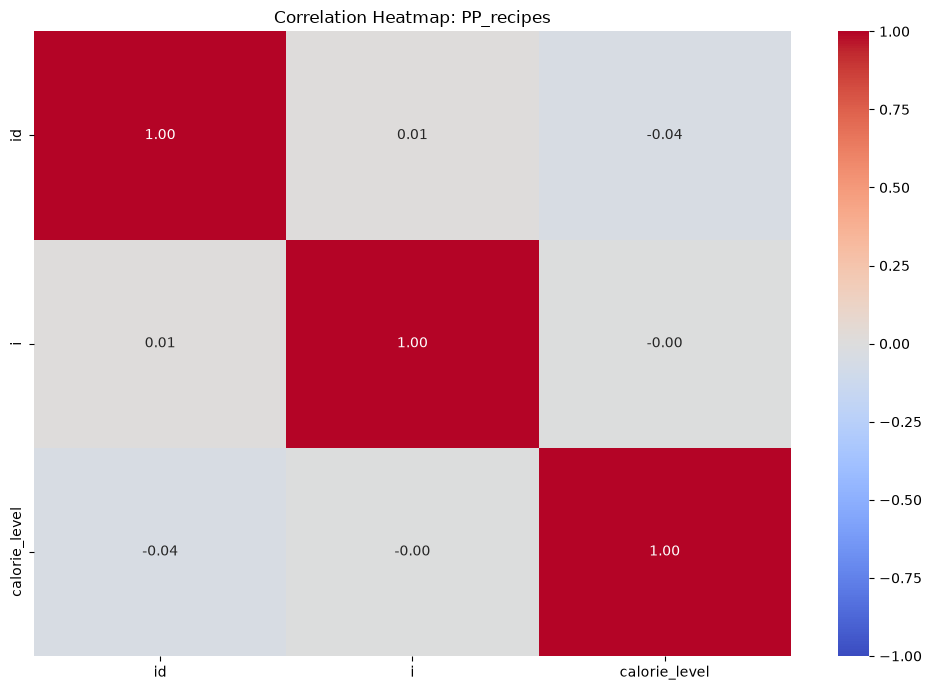


Numeric feature distributions: fruit-prices-2023


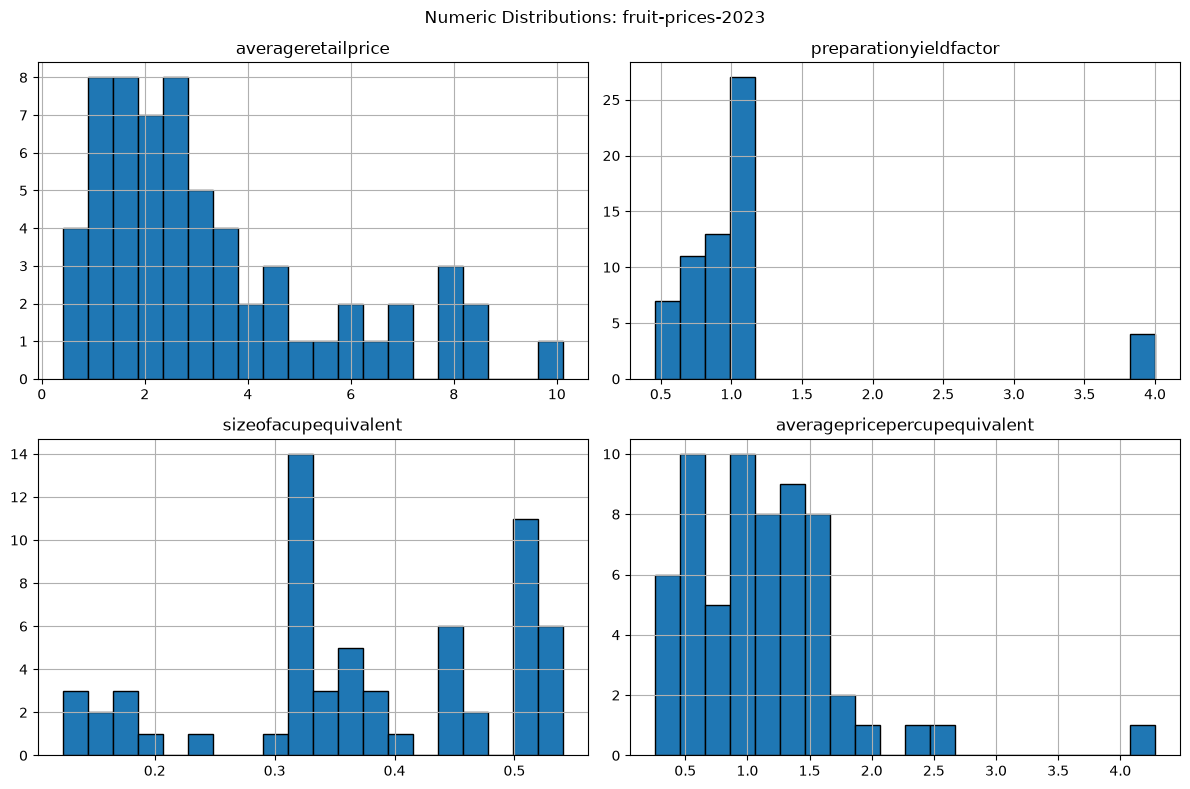

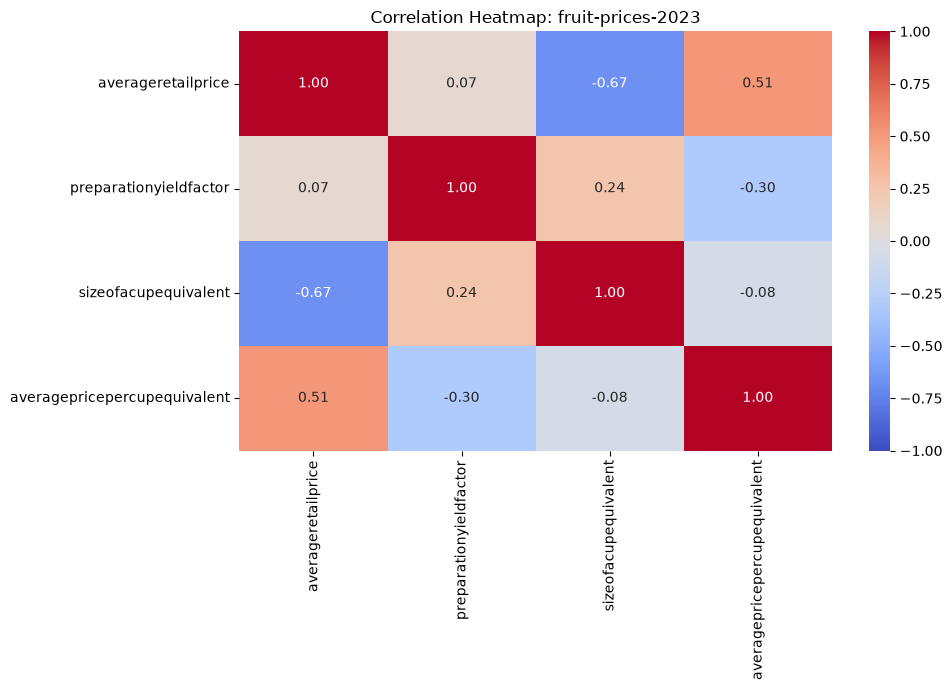


Numeric feature distributions: kroger_produce_raw


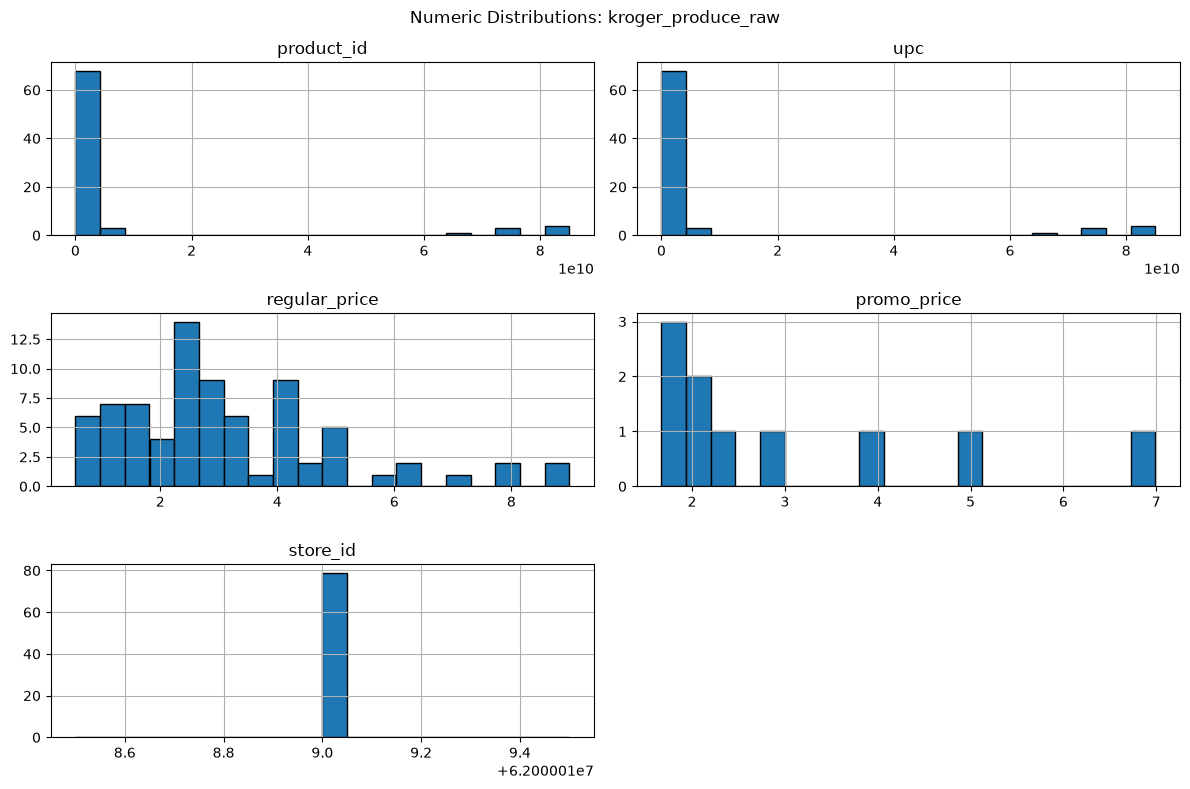

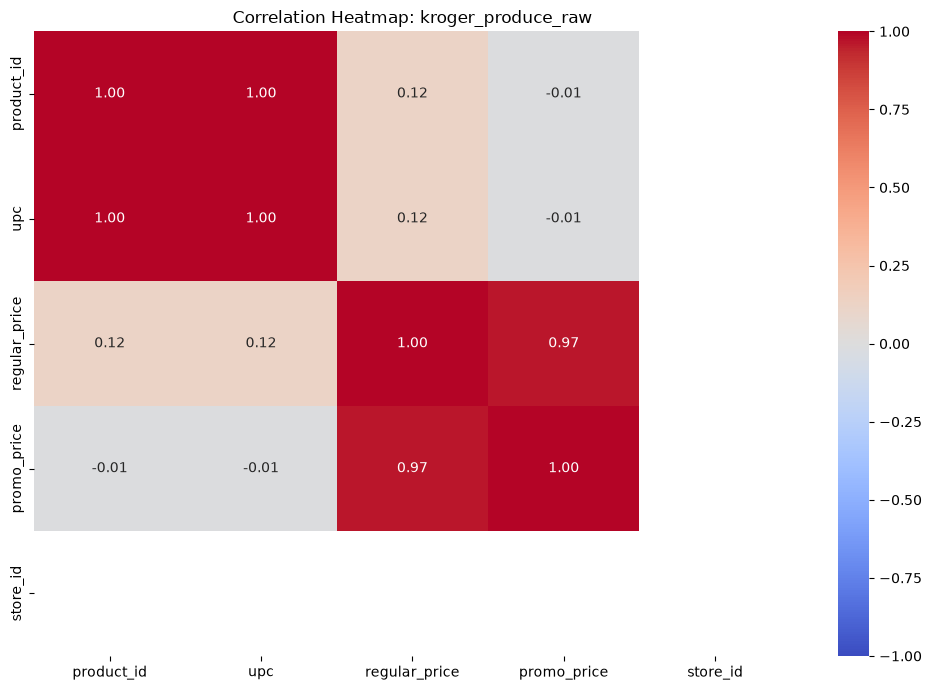


Numeric feature distributions: vegetable-prices-2023


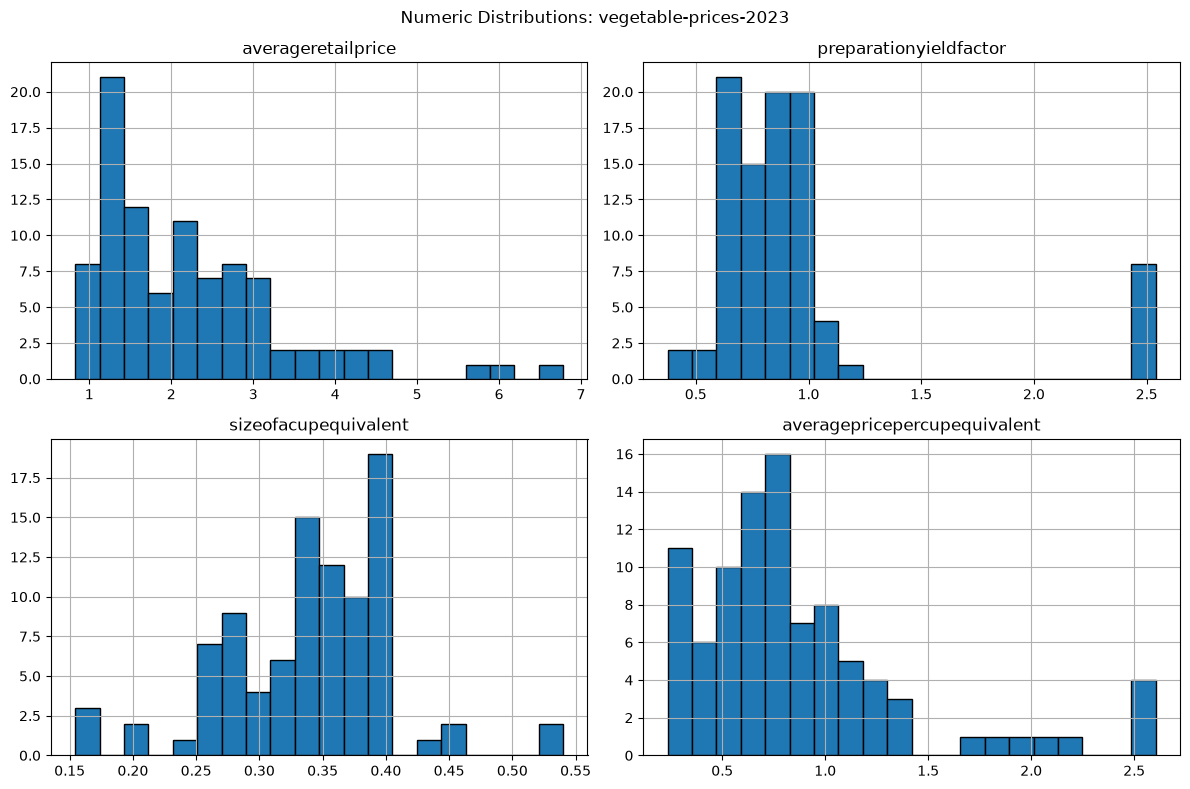

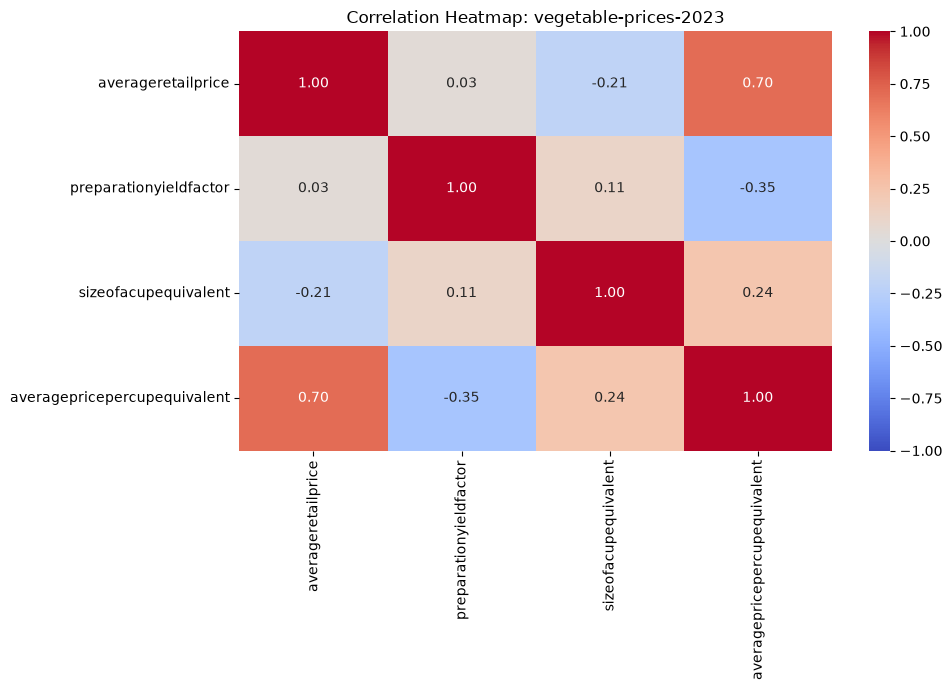

In [13]:
for name, df in cleaned_datasets.items():
    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.empty:
        print(f"No numeric columns to plot for {name}.")
        continue

    print(f"\nNumeric feature distributions: {name}")

    numeric_df.hist(
        bins=20,
        figsize=(12, 8),
        edgecolor="black"
    )

    plt.suptitle(f"Numeric Distributions: {name}")
    plt.tight_layout()
    plt.show()

    if numeric_df.shape[1] >= 2:
        correlation = numeric_df.corr()

        plt.figure(figsize=(10, 7))

        sns.heatmap(
            correlation,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            vmin=-1,
            vmax=1
        )

        plt.title(f"Correlation Heatmap: {name}")
        plt.tight_layout()
        plt.show()

### Identify likely recipe datasets based on column names

In [14]:
recipe_candidates = []

for name, df in cleaned_datasets.items():
    ingredient_columns = [
        col for col in df.columns
        if "ingredient" in col.lower()
    ]

    name_columns = [
        col for col in df.columns
        if col.lower() in ["name", "recipe_name", "title", "recipe_title"]
    ]

    if ingredient_columns:
        recipe_candidates.append({
            "dataset": name,
            "ingredient_columns": ingredient_columns,
            "name_columns": name_columns,
            "rows": len(df)
        })

recipe_candidates_df = pd.DataFrame(recipe_candidates)

if recipe_candidates_df.empty:
    print("No likely recipe dataset found.")
    print("Check the dataset columns in Cell 8.")
else:
    display(recipe_candidates_df)

,dataset,ingredient_columns,name_columns,rows
0,PP_recipes,"[ingredient_tokens, ingredient_ids]",[],178265


Missing recipe IDs: 0
Missing ingredient lists: 0


,id,ingredient_tokens,ingredients_clean,ingredient_text_length
0,424415,"[[2911, 1019, 249, 6878], [1353], [6953], [15341, 3261], [2056, 857, 643, 1631, 20480]]","[[2911, 1019, 249, 6878], [1353], [6953], [15341, 3261], [2056, 857, 643, 1631, 20480]]",87
1,146223,"[[17918], [25916], [2507, 6444], [8467, 1179], [8780], [6812], [4370, 2653, 18376], [2654, 5581, 34904, 5940], [1534...","[[17918], [25916], [2507, 6444], [8467, 1179], [8780], [6812], [4370, 2653, 18376], [2654, 5581, 34904, 5940], [1534...",151
2,312329,"[[5867, 24176], [1353], [6953], [1301, 11332], [21453, 8361], [25845, 8111, 11332], [23488, 8361], [37754, 10734], [...","[[5867, 24176], [1353], [6953], [1301, 11332], [21453, 8361], [25845, 8111, 11332], [23488, 8361], [37754, 10734], [...",289
3,74301,"[[1270, 1645, 28447], [21601], [27952, 29471, 484], [31843], [6821], [9514, 4914], [10444], [692, 37297, 17128]]","[[1270, 1645, 28447], [21601], [27952, 29471, 484], [31843], [6821], [9514, 4914], [10444], [692, 37297, 17128]]",112
4,76272,"[[1430, 11434], [1430, 17027], [1615, 23, 695, 2338, 6821], [13134, 2555, 29273, 9410]]","[[1430, 11434], [1430, 17027], [1615, 23, 695, 2338, 6821], [13134, 2555, 29273, 9410]]",87
5,465171,"[[13731, 30684, 260, 245, 17843, 25592, 10601], [1353], [21190], [6444], [2548, 8797], [3753, 2044, 5409], [13731, 7...","[[13731, 30684, 260, 245, 17843, 25592, 10601], [1353], [21190], [6444], [2548, 8797], [3753, 2044, 5409], [13731, 7...",155
6,163861,"[[31801, 12395, 25808], [17918], [6953], [11332], [8441], [6796, 5940], [5867, 500, 246, 21118, 17729], [6020], [8780]]","[[31801, 12395, 25808], [17918], [6953], [11332], [8441], [6796, 5940], [5867, 500, 246, 21118, 17729], [6020], [8780]]",119
7,186383,"[[17918], [25916], [15473, 8361], [15473, 10166], [6953], [2507, 6444], [6020], [15000, 18347], [637, 15, 5940], [53...","[[17918], [25916], [15473, 8361], [15473, 10166], [6953], [2507, 6444], [6020], [15000, 18347], [637, 15, 5940], [53...",126
8,116395,"[[17918], [36374, 3388, 650, 256, 6444], [23618, 5940], [578, 2916, 996], [8780], [1454, 1143, 7406], [2417, 1454, 3...","[[17918], [36374, 3388, 650, 256, 6444], [23618, 5940], [578, 2916, 996], [8780], [1454, 1143, 7406], [2417, 1454, 3...",183
9,303460,"[[559, 1164, 6020], [511, 532, 543, 241], [6647, 26285], [548, 27862, 10734], [1055, 11, 4364, 10107], [827, 6591], ...","[[559, 1164, 6020], [511, 532, 543, 241], [6647, 26285], [548, 27862, 10734], [1055, 11, 4364, 10107], [827, 6591], ...",166


Recipes with missing ingredients: 0


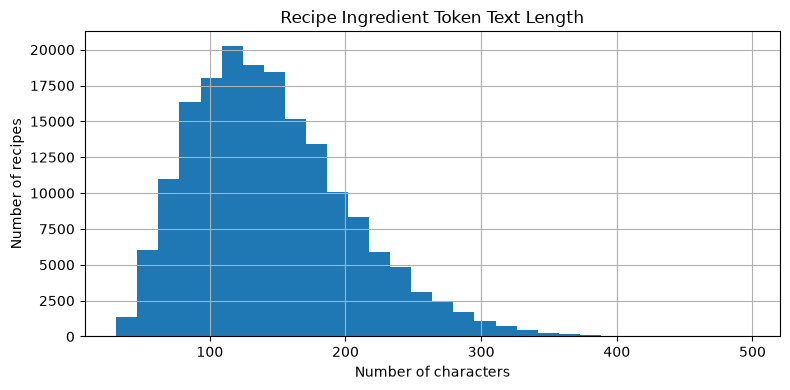

In [16]:

RECIPE_DATASET_NAME = "PP_recipes"
RECIPE_NAME_COLUMN = "id"
INGREDIENT_COLUMN = "ingredient_tokens"

if RECIPE_DATASET_NAME not in cleaned_datasets:
    print("Set RECIPE_DATASET_NAME to a dataset listed in Cell 14.")
else:
    recipes = cleaned_datasets[RECIPE_DATASET_NAME].copy()

    if INGREDIENT_COLUMN not in recipes.columns:
        print("Ingredient column not found.")
        print("Available columns:", recipes.columns.tolist())
    else:
        print("Missing recipe IDs:", int(recipes[RECIPE_NAME_COLUMN].isna().sum()))
        print("Missing ingredient lists:", int(recipes[INGREDIENT_COLUMN].isna().sum()))

        recipes["ingredients_clean"] = (
            recipes[INGREDIENT_COLUMN]
            .astype("string")
            .str.lower()
            .str.strip()
            .replace("", pd.NA)
        )

        recipes["ingredient_text_length"] = (
            recipes["ingredients_clean"].fillna("").str.len()
        )

        display(
            recipes[
                [
                    RECIPE_NAME_COLUMN,
                    INGREDIENT_COLUMN,
                    "ingredients_clean",
                    "ingredient_text_length"
                ]
            ].head(10)
        )

        print(
            "Recipes with missing ingredients:",
            int(recipes["ingredients_clean"].isna().sum())
        )

        recipes["ingredient_text_length"].hist(bins=30, figsize=(8, 4))
        plt.title("Recipe Ingredient Token Text Length")
        plt.xlabel("Number of characters")
        plt.ylabel("Number of recipes")
        plt.tight_layout()
        plt.show()

        recipes.to_csv(
            PROCESSED_DIR / "recipes_cleaned.csv",
            index=False
        )


,search_term,description,size,effective_price
0,bananas,Fresh Bunch of Bananas – 5-7 Bananas,1 lb,0.55
2,bananas,Fresh Plantain - Single,1 ea,0.67
15,apples,Small Gala Apple – Each,1 each,0.75
1,bananas,Fresh Bunch of Organic Bananas – 5-7 Bananas,1 lb,0.79
23,potatoes,Russet Potato,1 lb,0.89
70,bell pepper,Fresh Large Green Bell Pepper,1 ct,0.89
50,onions,Jumbo Yellow Onions,1 lb,0.99
51,onions,Jumbo White Onions,1 lb,1.19
60,tomatoes,Fresh Roma Tomato,1 lb,1.29
57,onions,Green Onions,1 each,1.29


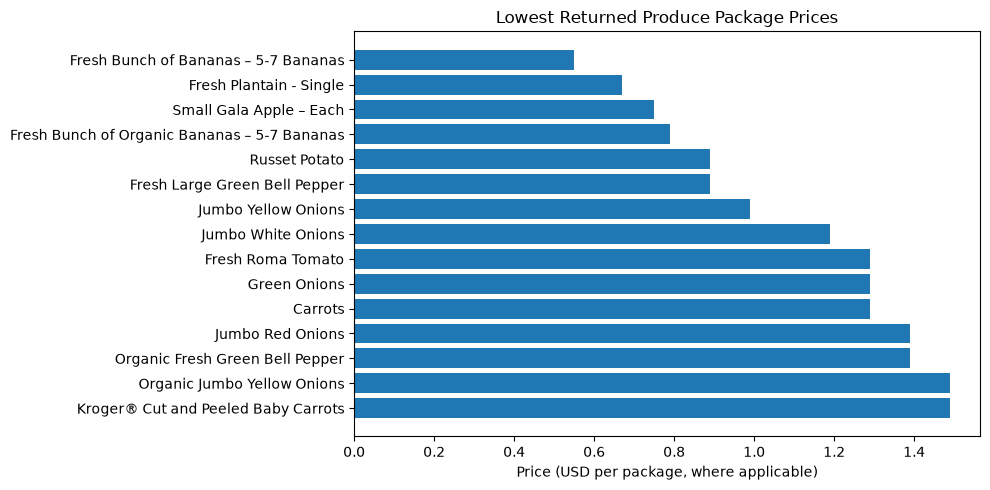

In [17]:
if price_dataset_name is not None:
    valid_prices = prices.loc[
        prices[selected_price_column].notna()
        & (prices[selected_price_column] > 0)
    ].copy()

    sort_columns = [
        col for col in [
            "search_term", "description", "size",
            selected_price_column
        ]
        if col in valid_prices.columns
    ]

    cheapest_products = valid_prices.sort_values(
        selected_price_column
    )

    display(cheapest_products[sort_columns].head(20))

    cheapest_products.to_csv(
        PROCESSED_DIR / "cheapest_package_prices.csv",
        index=False
    )

    plt.figure(figsize=(10, 5))

    plot_labels = (
        cheapest_products["description"].fillna("Unknown product").astype(str)
        if "description" in cheapest_products.columns
        else cheapest_products.index.astype(str)
    )

    plot_data = cheapest_products.head(15).copy()
    plot_labels = (
        plot_data["description"].fillna("Unknown product").astype(str)
        if "description" in plot_data.columns
        else plot_data.index.astype(str)
    )

    plt.barh(
        plot_labels.iloc[::-1],
        plot_data[selected_price_column].iloc[::-1]
    )

    plt.title("Lowest Returned Produce Package Prices")
    plt.xlabel("Price (USD per package, where applicable)")
    plt.tight_layout()
    plt.show()
else:
    print("No price dataset is available to rank.")